# Notebook 01 — Dataset Audit

**Track A · Soccer Event Transformer · Identity × Context project**

| Item | Content |
|---|---|
| **Research question (project level)** | When a player's identity suggests one action and the current game situation suggests another, what does a trained model do? Track A trains and freezes the model that is later analysed mechanistically. |
| **Purpose of this notebook** | Verify the prepared dataset before any model is trained: schema, ordering, windows, splits, leakage and class balance. Nothing is trained here. |
| **Data** | `cleaned_dataset.parquet`: 658,905 on-ball events from 350 StatsBomb open-data matches, one row per event. |
| **Scientific decisions made here** | (1) How to handle features whose values depend on the action being predicted (Section 8). (2) Whether to rebalance classes (Section 9). Each decision is stated with its evidence. |

In [2]:
# ---------------------------------------------------------------------------
# Environment setup (identical at the top of every Track A notebook)
# ---------------------------------------------------------------------------
import os
import sys
import json
import time
from pathlib import Path

IN_COLAB = "google.colab" in sys.modules
if IN_COLAB:
    from google.colab import drive
    drive.mount("/content/drive")

# PROJECT_DIR holds code (src/), data artifacts, runs, results and the release.
PROJECT_DIR = Path(os.environ.get("TRACK_A_DIR", "/content/drive/MyDrive/soccer_mi/track_a"))
# DATASET_PATH is the prepared research dataset (one row per on-ball event).
DATASET_PATH = Path(os.environ.get("TRACK_A_DATASET", str(PROJECT_DIR / "data" / "cleaned_dataset.parquet")))
# RUN_MODE = "full"  -> real research runs (use this for every reported number)
# RUN_MODE = "smoke" -> tiny code check only; outputs go to PROJECT_DIR/smoke and are NOT results
RUN_MODE = os.environ.get("TRACK_A_RUN_MODE", "full")
assert RUN_MODE in ("full", "smoke")

PROJECT_DIR.mkdir(parents=True, exist_ok=True)
os.chdir(PROJECT_DIR)
if str(PROJECT_DIR) not in sys.path:
    sys.path.insert(0, str(PROJECT_DIR))
(PROJECT_DIR / "src").mkdir(exist_ok=True)
(PROJECT_DIR / "tests").mkdir(exist_ok=True)

# Data-audit artifacts are cheap and always produced in full mode.
ARTIFACTS_DIR = PROJECT_DIR / "artifacts"
# Training runs, results and figures are separated by run mode so a smoke check can never
# overwrite or be confused with a research result.
OUTPUT_DIR = PROJECT_DIR if RUN_MODE == "full" else PROJECT_DIR / "smoke"
RUNS_DIR = OUTPUT_DIR / "runs"
RESULTS_DIR = OUTPUT_DIR / "results"
FIGURES_DIR = OUTPUT_DIR / "figures"
for folder in [ARTIFACTS_DIR, RUNS_DIR, RESULTS_DIR, FIGURES_DIR]:
    folder.mkdir(parents=True, exist_ok=True)

print("Colab:", IN_COLAB, "| RUN_MODE:", RUN_MODE)
print("PROJECT_DIR:", PROJECT_DIR)
print("DATASET_PATH:", DATASET_PATH, "| exists:", DATASET_PATH.exists())

Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Colab: True | RUN_MODE: full
PROJECT_DIR: /content/drive/MyDrive/soccer_mi/track_a
DATASET_PATH: /content/drive/MyDrive/soccer_mi/track_a/data/cleaned_dataset.parquet | exists: True


## 1. Key terms used in this notebook

| Term | Meaning in this project |
|---|---|
| **Event** | One on-ball action by an identified player, with a pitch location (a pass, a carry, a shot, a tackle...). One row of the dataset. |
| **Target (action class)** | The thing the model must predict: which of 15 action classes the event belongs to (`action_id`, 0–14). |
| **Pre-action information** | Anything knowable *before* the player performs the action: who the player is, where the ball is, the time, the score, what happened in earlier events. The model may only use pre-action information. |
| **Leakage** | Information about the answer that sneaks into the input. A model that sees leaked information looks accurate but has learned nothing real. |
| **Identity** | Who is acting: the player, their team, their role (playing position) and — as a grouping variable — the competition. |
| **Context** | The situation the action happens in: location, time, score and possession state, and what happened in previous events. |
| **Period** | A half of a match (1, 2) or extra-time period (3, 4). Sequences never cross from one period into another. |
| **Model-ready window** | 32 consecutive events from the same match and period. This is one training example. Windows start every 8 events (the *stride*), so consecutive windows overlap by 24 events. |
| **Split** | The dataset is divided by **match** into train (fit the model), validation (choose settings) and test (final, one-time evaluation). A match belongs to exactly one split. |

## 2. Load the dataset and fingerprint it

The file is loaded and its SHA-256 hash is recorded. A *hash* is a short fingerprint of the file's bytes: if one byte changes, the hash changes, so the hash identifies the exact dataset version the results refer to.

The events are sorted by match, period and the original StatsBomb event `index`, which is the chronological order of events within a match. A column `period_offset` (0, 1, 2, … within each match-period) is added; it is used to build windows. The loading functions are written to `src/data.py` so that all notebooks read the data in the same way.

In [ ]:
%%writefile src/data.py
"""
src/data.py — data preparation for Track A.

This file is written by notebooks 01 and 02. Every function is explained in the notebook
cell that writes it.
"""
import hashlib
import json
from pathlib import Path

import numpy as np
import pandas as pd

# The 15 action classes the model predicts (the target vocabulary).
ACTION_NAMES = [
    "PASS_SHORT", "PASS_LONG", "CROSS", "CARRY", "DRIBBLE", "SHOT", "CLEARANCE",
    "RECOVERY", "INTERCEPTION", "DUEL", "FOUL_WON", "FOUL_COMMITTED", "GK_ACTION",
    "LOSS", "OTHER",
]
NUM_ACTIONS = len(ACTION_NAMES)

# Code 15 ("END") appears only in the history feature prev_action_id, on the first event of a
# period, meaning "there is no previous event". It is never a prediction target.
END_ACTION_CODE = 15


def file_sha256(path):
    """Return the SHA-256 fingerprint of a file (reads it in 1 MB blocks)."""
    digest = hashlib.sha256()
    with open(path, "rb") as handle:
        while True:
            block = handle.read(1024 * 1024)
            if not block:
                break
            digest.update(block)
    return digest.hexdigest()


def load_events(dataset_path):
    """Load the event table in chronological order and add `period_offset`.

    period_offset = 0 for the first event of a (match, period), 1 for the second, and so on.
    """
    events = pd.read_parquet(dataset_path)
    events = events.sort_values(["match_id", "period", "index"]).reset_index(drop=True)
    events["period_offset"] = events.groupby(["match_id", "period"]).cumcount()
    return events

Overwriting src/data.py


In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import importlib
import src.data as data
importlib.reload(data)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["axes.grid"] = True
plt.rcParams["grid.alpha"] = 0.3

dataset_hash = data.file_sha256(DATASET_PATH)
events = data.load_events(DATASET_PATH)

print("Rows (events):", len(events))
print("Columns:", events.shape[1])
print("SHA-256:", dataset_hash)

with open(ARTIFACTS_DIR / "dataset_hash.json", "w") as handle:
    json.dump({"dataset_file": DATASET_PATH.name, "sha256": dataset_hash,
               "n_rows": int(len(events))}, handle, indent=2)

Rows (events): 658905
Columns: 41
SHA-256: 2fe8019fb59f8060f77ae0b81eba3df2077a3fd50c02f601ed7f401b3855fc5b


## 3. Schema audit

**What this step does.** For every column the table below reports its type, missing values, observed range, meaning, where it comes from, whether it is available *before* the action happens, and its role:

* **model input** — the model may see it;
* **target** — the answer the model must predict;
* **target-side** — describes the answer (for example where the action ended); never an input;
* **reference** — kept for tracing results back to football (names, raw coordinates, ids).

"Pre-action?" is answered by reasoning about how the value is produced, not by assumption. Columns marked **audit** are checked in Section 8.

In [ ]:
# meaning, source, pre-action availability, role — written by hand from the column definitions
column_documentation = {
    "match_id":           ("Match identifier", "StatsBomb match", "yes", "reference"),
    "event_id":           ("Event identifier (UUID)", "StatsBomb event", "yes", "reference"),
    "index":              ("Chronological order of the event within its match", "StatsBomb event", "yes", "reference"),
    "period":             ("Match period: 1, 2 = halves; 3, 4 = extra time", "StatsBomb event", "yes", "model input"),
    "minute":             ("Match clock minute", "StatsBomb event", "yes", "reference"),
    "second":             ("Match clock second", "StatsBomb event", "yes", "reference"),
    "t_period_s":         ("Seconds since the start of the period", "derived from timestamp", "yes", "reference"),
    "possession":         ("StatsBomb possession counter within the match", "StatsBomb event", "audit", "reference"),
    "possession_team_id": ("Team StatsBomb assigns the possession to", "StatsBomb event", "audit", "reference"),
    "team_id":            ("Team of the acting player", "StatsBomb event", "yes", "reference (encoded as team)"),
    "player_id":          ("Acting player", "StatsBomb event", "yes", "reference (encoded as player)"),
    "player_name":        ("Player name", "StatsBomb event", "yes", "reference"),
    "position_id":        ("Playing position (role) at the time of the event", "StatsBomb event", "yes", "reference (encoded as role)"),
    "position_name":      ("Role name", "StatsBomb event", "yes", "reference"),
    "type_name":          ("Raw StatsBomb event type", "StatsBomb event", "no — it is the answer", "target-side"),
    "x":                  ("Start x coordinate, 0–120, acting team attacks towards 120", "StatsBomb event", "yes", "reference"),
    "y":                  ("Start y coordinate, 0–80", "StatsBomb event", "yes", "reference"),
    "split":              ("train / val / test (assigned per match)", "project split", "—", "reference"),
    "competition_id":     ("Competition", "StatsBomb match", "yes", "reference (encoded as competition)"),
    "zone":               ("Start cell on a 12 x 8 grid (96 cells)", "derived from x, y", "yes", "model input"),
    "x_norm":             ("x / 120", "derived from x", "yes", "model input"),
    "y_norm":             ("y / 80", "derived from y", "yes", "model input"),
    "minute_bin":         ("5-minute bucket of the match clock (0–23)", "derived from minute", "yes", "model input"),
    "dt":                 ("log(1 + seconds since the previous event), clipped at 60 s", "derived", "yes", "model input"),
    "t_poss":             ("log(1 + seconds since the possession's first event), clipped at 600 s", "derived from possession", "audit", "model input (audit)"),
    "score_diff_idx":     ("Goal difference from the acting team's view, clipped to ±3, stored as 0–6", "derived", "yes if pre-goal", "model input (audit)"),
    "play_pattern_id":    ("How the current possession began (regular play, throw-in, ...)", "StatsBomb possession", "audit", "model input (audit)"),
    "poss_len":           ("Events so far in the current possession, capped at 20", "derived from possession", "audit", "model input (audit)"),
    "new_possession":     ("1 if the event is the first of a possession", "derived from possession", "audit", "model input (audit)"),
    "prev_action_id":     ("Action class of the previous event (15 = END: no previous event)", "derived", "yes", "model input"),
    "prev_outcome":       ("Previous event: 0 = successful, 1 = unsuccessful, 2 = not applicable", "derived", "yes", "model input"),
    "prev_end_zone":      ("Grid cell where the previous event ended", "derived", "yes", "model input"),
    "same_player_as_prev":("1 if the previous event had the same actor", "derived", "yes", "model input"),
    "action":             ("Action class name", "derived from type and details", "no — it is the answer", "target (name)"),
    "action_id":          ("Action class id 0–14", "derived", "no — it is the answer", "target"),
    "end_zone":           ("Grid cell where the current action ended", "derived", "no — happens after the action", "target-side"),
    "player_ix":          ("Player index built with a 300-event train threshold", "earlier encoding stage", "yes", "superseded (rebuilt in notebook 02)"),
    "team_ix":            ("Team index built on train", "earlier encoding stage", "yes", "superseded (rebuilt below)"),
    "role_ix":            ("Role index built on train", "earlier encoding stage", "yes", "superseded (rebuilt below)"),
    "comp_ix":            ("Competition index built on train", "earlier encoding stage", "yes", "superseded (rebuilt below)"),
}

schema_rows = []
for column in events.columns:
    if column == "period_offset":
        continue
    series = events[column]
    if pd.api.types.is_numeric_dtype(series):
        observed_range = f"{series.min()} … {series.max()}"
    else:
        observed_range = f"{series.nunique()} distinct values"
    meaning, source, pre_action, role = column_documentation.get(column, ("UNDOCUMENTED", "?", "?", "?"))
    schema_rows.append({
        "column": column,
        "dtype": str(series.dtype),
        "missing": int(series.isna().sum()),
        "observed range": observed_range,
        "distinct": int(series.nunique()),
        "meaning": meaning,
        "source": source,
        "pre-action?": pre_action,
        "role": role,
    })
schema_table = pd.DataFrame(schema_rows)
undocumented = schema_table[schema_table["meaning"] == "UNDOCUMENTED"]
print("Columns:", len(schema_table), "| undocumented:", len(undocumented), "| total missing values:", schema_table["missing"].sum())
pd.set_option("display.max_colwidth", 80)
schema_table

Columns: 40 | undocumented: 0 | total missing values: 0


,column,dtype,missing,observed range,distinct,meaning,source,pre-action?,role
0,match_id,int64,0,7494 … 4018355,350,Match identifier,StatsBomb match,yes,reference
1,event_id,str,0,658905 distinct values,658905,Event identifier (UUID),StatsBomb event,yes,reference
2,index,int64,0,5 … 4855,4718,Chronological order of the event within its match,StatsBomb event,yes,reference
3,period,int16,0,1 … 4,4,"Match period: 1, 2 = halves; 3, 4 = extra time",StatsBomb event,yes,model input
4,minute,int64,0,0 … 127,125,Match clock minute,StatsBomb event,yes,reference
5,second,int64,0,0 … 59,60,Match clock second,StatsBomb event,yes,reference
6,t_period_s,float64,0,0.001 … 3479.997,535476,Seconds since the start of the period,derived from timestamp,yes,reference
7,possession,int64,0,2 … 281,280,StatsBomb possession counter within the match,StatsBomb event,audit,reference
8,possession_team_id,int64,0,1 … 19107,228,Team StatsBomb assigns the possession to,StatsBomb event,audit,reference
9,team_id,int64,0,1 … 19107,228,Team of the acting player,StatsBomb event,yes,reference (encoded as team)


**RESULT.** Every column in the file is documented, with its type, range and role.

**OBSERVATION.** See the counts printed above the table: the number of undocumented columns and the total number of missing values. All categorical ranges match their declared sizes (for example 96 zones, 7 score states, 24 minute buckets).

**INTERPRETATION.** The file is internally complete. The absence of missing values is a property of how the table was built (rows without an actor or a location were removed earlier), not evidence that the raw data was complete.

**SCIENTIFIC SIGNIFICANCE.** The table separates what the model may see from what it must never see. Five columns are marked **audit**: their availability before the action is not obvious, and Section 8 tests them.

**LIMITATION.** "Pre-action?" for the non-audit columns rests on how each field is defined. The mechanical check in Section 8.4 confirms it for the columns that describe the action's result.

## 4. Split integrity

**Why this matters.** The model is scored on matches it never saw during training. If a match appeared in two splits, overlapping windows would let the model see near-copies of its test examples, and the test score would be too optimistic.

**Checks.** (1) Each match belongs to exactly one split. (2) Match and event counts per split. (3) A split manifest (the list of match ids per split) is saved so the split can be reproduced exactly.

In [ ]:
splits_per_match = events.groupby("match_id")["split"].nunique()
matches_in_more_than_one_split = int((splits_per_match > 1).sum())

split_summary = events.groupby("split").agg(matches=("match_id", "nunique"), events=("event_id", "size"))
split_summary = split_summary.loc[["train", "val", "test"]]
split_summary["share of events (%)"] = (100 * split_summary["events"] / len(events)).round(2)
print("Matches appearing in more than one split:", matches_in_more_than_one_split)

train_matches = set(events.loc[events.split == "train", "match_id"])
val_matches = set(events.loc[events.split == "val", "match_id"])
test_matches = set(events.loc[events.split == "test", "match_id"])
print("train ∩ val:", len(train_matches & val_matches),
      "| train ∩ test:", len(train_matches & test_matches),
      "| val ∩ test:", len(val_matches & test_matches))

split_manifest = {
    "train": sorted(int(m) for m in train_matches),
    "val": sorted(int(m) for m in val_matches),
    "test": sorted(int(m) for m in test_matches),
}
with open(ARTIFACTS_DIR / "split_manifest.json", "w") as handle:
    json.dump(split_manifest, handle)

expected = pd.DataFrame({"matches": [280, 35, 35], "events": [525893, 68003, 65009]}, index=["train", "val", "test"])
split_summary.join(expected, rsuffix=" (expected)")

Matches appearing in more than one split: 0
train ∩ val: 0 | train ∩ test: 0 | val ∩ test: 0


,matches,events,share of events (%),matches (expected),events (expected)
split,,,,,
train,280,525893,79.81,280,525893
val,35,68003,10.32,35,68003
test,35,65009,9.87,35,65009


**RESULT.** No match appears in more than one split, and the match and event counts equal the figures in the dataset specification (shown side by side).

**INTERPRETATION.** The split is match-level, as required. Windows are built inside a single match and period (Section 6), so no window can contain events from two splits.

**LIMITATION.** Players and teams do recur across splits. That is intended: the research question concerns how a model uses what it has learned about *known* players. Results therefore describe familiar players, not generalisation to unseen players.

## 5. Sequence integrity

The model reads events in order and uses "history" features that describe the previous event. These checks confirm that the order and the history columns are correct. Each check counts **violations**; zero means the check passes.

| Check | What is verified |
|---|---|
| Chronological order | `index` strictly increases within every match-period |
| Period length | every match-period has at least 32 events (otherwise no window could be formed) |
| Previous action | `prev_action_id` of an event equals `action_id` of the event before it; the first event of a period carries END (15) |
| Previous end zone | `prev_end_zone` equals the `end_zone` of the event before it |
| Same player | `same_player_as_prev` equals "this actor = previous actor" |
| Time gap | `dt` equals log(1 + min(seconds since previous event, 60)) |
| Possession boundaries | `new_possession` is 1 exactly where the possession counter changes, and `poss_len` restarts at 0 there |

In [ ]:
group = events.groupby(["match_id", "period"])
is_first_in_period = events["period_offset"] == 0

sequence_checks = {}

index_step = group["index"].diff()
sequence_checks["index not strictly increasing"] = int((index_step[~is_first_in_period] <= 0).sum())

period_lengths = group.size()
sequence_checks["match-periods shorter than 32 events"] = int((period_lengths < 32).sum())

previous_action = group["action_id"].shift(1)
mismatch_prev_action = (events["prev_action_id"] != previous_action) & ~is_first_in_period
sequence_checks["prev_action_id != previous action"] = int(mismatch_prev_action.sum())
sequence_checks["first event of period without END code"] = int((events.loc[is_first_in_period, "prev_action_id"] != data.END_ACTION_CODE).sum())

previous_end_zone = group["end_zone"].shift(1)
sequence_checks["prev_end_zone != previous end_zone"] = int(((events["prev_end_zone"] != previous_end_zone) & ~is_first_in_period).sum())

previous_player = group["player_id"].shift(1)
same_player_recomputed = (events["player_id"] == previous_player).astype(int)
sequence_checks["same_player_as_prev mismatch"] = int(((events["same_player_as_prev"] != same_player_recomputed) & ~is_first_in_period).sum())

seconds_since_previous = group["t_period_s"].diff().clip(lower=0, upper=60)
dt_recomputed = np.log1p(seconds_since_previous)
dt_error = (events["dt"] - dt_recomputed).abs()
sequence_checks["dt differs from recomputation by > 1e-3"] = int((dt_error[~is_first_in_period] > 1e-3).sum())

possession_changed = group["possession"].diff().fillna(1) != 0
sequence_checks["new_possession != possession counter change"] = int((events["new_possession"].astype(bool) != possession_changed).sum())
sequence_checks["poss_len not 0 at a new possession"] = int((events.loc[events["new_possession"] == 1, "poss_len"] != 0).sum())

sequence_table = pd.DataFrame({"violations": sequence_checks})
sequence_table["verdict"] = np.where(sequence_table["violations"] == 0, "PASS", "CHECK")
print("Match-periods:", len(period_lengths), "| shortest period:", int(period_lengths.min()), "events")
sequence_table

Match-periods: 706 | shortest period: 234 events


,violations,verdict
index not strictly increasing,0,PASS
match-periods shorter than 32 events,0,PASS
prev_action_id != previous action,0,PASS
first event of period without END code,0,PASS
prev_end_zone != previous end_zone,0,PASS
same_player_as_prev mismatch,0,PASS
dt differs from recomputation by > 1e-3,0,PASS
new_possession != possession counter change,0,PASS
poss_len not 0 at a new possession,0,PASS


**How to read this table.** Each row is an automated check; the verdict is PASS when there are zero violations. Any CHECK row is examined in the cell below rather than ignored.

In [ ]:
# Inspect any check that did not pass, so a failure is explained rather than hidden.
failed_checks = sequence_table[sequence_table["verdict"] != "PASS"]
if len(failed_checks) == 0:
    print("All sequence checks pass.")
else:
    print("Checks needing explanation:")
    print(failed_checks)
    if sequence_checks["dt differs from recomputation by > 1e-3"] > 0:
        bad_rows = dt_error[~is_first_in_period] > 1e-3
        print("\nExamples of dt differences:")
        print(pd.DataFrame({"dt stored": events.loc[bad_rows[bad_rows].index, "dt"],
                            "dt recomputed": dt_recomputed[bad_rows[bad_rows].index]}).head())

All sequence checks pass.


## 6. Model-ready windows and the evaluation view

### 6.1 Training windows

**Definition.** A *model-ready window* is 32 consecutive events from one match-period. The first window starts at the first event of the period; each next window starts 8 events later (stride 8). A window is only formed if all 32 events exist, so windows never cross a match or period boundary and never need padding.

**Target alignment.** Position *i* of a window holds the pre-action features of event *i* and is trained to predict the action of that same event *i*. Because the model uses *causal* attention (defined in notebook 03: a position can only look at itself and earlier positions), position *i* never sees events after it. All 32 positions of a window are training targets.

The prepared dataset stores events, not windows; the windows are rebuilt here from the rule above and checked against the specified counts.

In [ ]:
%%writefile -a src/data.py

def build_windows(events, context_length, stride, split=None):
    """Build model-ready windows.

    Returns an integer array of shape [n_windows, context_length]. Each row lists the row
    numbers (into `events`) of `context_length` consecutive events from ONE match-period.
    Consecutive windows start `stride` events apart. A window is only formed if it is full,
    so no window crosses a match or period boundary and no padding is needed.
    """
    if split is None:
        selected = events
    else:
        selected = events[events["split"] == split]

    windows = []
    for _, period_events in selected.groupby(["match_id", "period"], sort=True):
        row_numbers = period_events.index.to_numpy()
        n_events = len(row_numbers)
        start = 0
        while start + context_length <= n_events:
            windows.append(row_numbers[start:start + context_length])
            start = start + stride
    return np.array(windows, dtype=np.int64)


def build_evaluation_view(events, split, context_length, stride):
    """Assign every event of a split to exactly ONE (window, position) for evaluation.

    Training windows overlap, so an event appears in up to context_length / stride windows,
    each time with a different amount of history before it. Scoring all copies would count
    the same event several times. Here each event is scored once, in the window where it has
    the MOST preceding history (the earliest window that contains it).

    The regular windows are the training windows. If the last events of a period are not
    covered by any regular window, one extra window ending at the last event is added
    (evaluation only), so that every event is scored.

    Returns a dict with:
      windows       [n_windows, context_length] row numbers
      event_rows    [n_events]  row number of each scored event
      window_index  [n_events]  which window the event is scored in
      position      [n_events]  its position inside that window
    """
    selected = events[events["split"] == split]
    all_windows = []
    event_rows = []
    window_index = []
    positions = []

    for _, period_events in selected.groupby(["match_id", "period"], sort=True):
        row_numbers = period_events.index.to_numpy()
        n_events = len(row_numbers)
        starts = list(range(0, n_events - context_length + 1, stride))
        tail_start = n_events - context_length
        if starts[-1] != tail_start:
            starts.append(tail_start)

        chosen_window = np.full(n_events, -1, dtype=np.int64)
        chosen_position = np.full(n_events, -1, dtype=np.int64)
        for start in starts:
            window_number = len(all_windows)
            all_windows.append(row_numbers[start:start + context_length])
            for position in range(context_length):
                offset = start + position
                # keep the first (earliest) window that contains this event
                if chosen_window[offset] == -1:
                    chosen_window[offset] = window_number
                    chosen_position[offset] = position

        event_rows.extend(row_numbers.tolist())
        window_index.extend(chosen_window.tolist())
        positions.extend(chosen_position.tolist())

    return {
        "windows": np.array(all_windows, dtype=np.int64),
        "event_rows": np.array(event_rows, dtype=np.int64),
        "window_index": np.array(window_index, dtype=np.int64),
        "position": np.array(positions, dtype=np.int64),
    }

Appending to src/data.py


In [ ]:
importlib.reload(data)
CONTEXT_LENGTH = 32
STRIDE = 8

window_counts = {}
window_problems = {}
for split_name in ["train", "val", "test"]:
    split_windows = data.build_windows(events, CONTEXT_LENGTH, STRIDE, split=split_name)
    window_counts[split_name] = len(split_windows)
    # every window must come from one match and one period, in increasing order
    window_matches = events["match_id"].to_numpy()[split_windows]
    window_periods = events["period"].to_numpy()[split_windows]
    crosses_match = (window_matches != window_matches[:, :1]).any(axis=1)
    crosses_period = (window_periods != window_periods[:, :1]).any(axis=1)
    not_consecutive = (np.diff(split_windows, axis=1) != 1).any(axis=1)
    window_problems[split_name] = int(crosses_match.sum() + crosses_period.sum() + not_consecutive.sum())

window_table = pd.DataFrame({"windows": window_counts, "problems": window_problems})
window_table["expected"] = pd.Series({"train": 63787, "val": 8261, "test": 7886})
window_table.loc["total"] = window_table.sum()
print("Training targets per epoch (train windows x 32):", window_counts["train"] * CONTEXT_LENGTH)
window_table

Training targets per epoch (train windows x 32): 2041184


,windows,problems,expected
train,63787,0,63787
val,8261,0,8261
test,7886,0,7886
total,79934,0,79934


**RESULT.** The rebuilt window counts equal the specified counts in every split (79,934 in total), and no window crosses a match or period boundary or skips an event.

**INTERPRETATION.** The windowing rule is reconstructed exactly. Because windows are rebuilt from the event table by a documented function, they can also be rebuilt for other context lengths (16 and 64, needed in notebook 05) with the same rule.

### 6.2 Coverage and the one-prediction-per-event evaluation view

**Why this is needed.** With a window length of 32 and a stride of 8, most events appear in four different windows: once near the end of a window (much history before it) and up to three times earlier in other windows (less history). If every copy were scored, the same event would be counted up to four times, and its score would mix different amounts of history.

**Decision.** For validation and test metrics, every event is scored **exactly once**, in the window where it has the most history before it. Events at the very end of a period that no regular window reaches get one extra "tail" window (evaluation only). Training still uses all 32 positions of every regular window.

In [ ]:
coverage_rows = []
evaluation_views = {}
for split_name in ["train", "val", "test"]:
    split_windows = data.build_windows(events, CONTEXT_LENGTH, STRIDE, split=split_name)
    split_event_rows = events.index[events["split"] == split_name].to_numpy()
    appearances = np.zeros(len(events), dtype=np.int64)
    for window in split_windows:
        appearances[window] += 1
    appearances = appearances[split_event_rows]

    view = data.build_evaluation_view(events, split_name, CONTEXT_LENGTH, STRIDE)
    evaluation_views[split_name] = view
    coverage_rows.append({
        "split": split_name,
        "events": len(split_event_rows),
        "events in no training window": int((appearances == 0).sum()),
        "mean appearances per event": round(float(appearances.mean()), 3),
        "events scored in evaluation view": len(view["event_rows"]),
        "each event scored exactly once": bool(len(np.unique(view["event_rows"])) == len(split_event_rows)),
        "evaluation windows (incl. tail)": len(view["windows"]),
        "median evaluation position": int(np.median(view["position"])),
    })
coverage_table = pd.DataFrame(coverage_rows).set_index("split")
coverage_table

,events,events in no training window,mean appearances per event,events scored in evaluation view,each event scored exactly once,evaluation windows (incl. tail),median evaluation position
split,,,,,,,
train,525893,2013,3.881,525893,True,64298,27
val,68003,235,3.887,68003,True,8319,27
test,65009,241,3.882,65009,True,7949,27


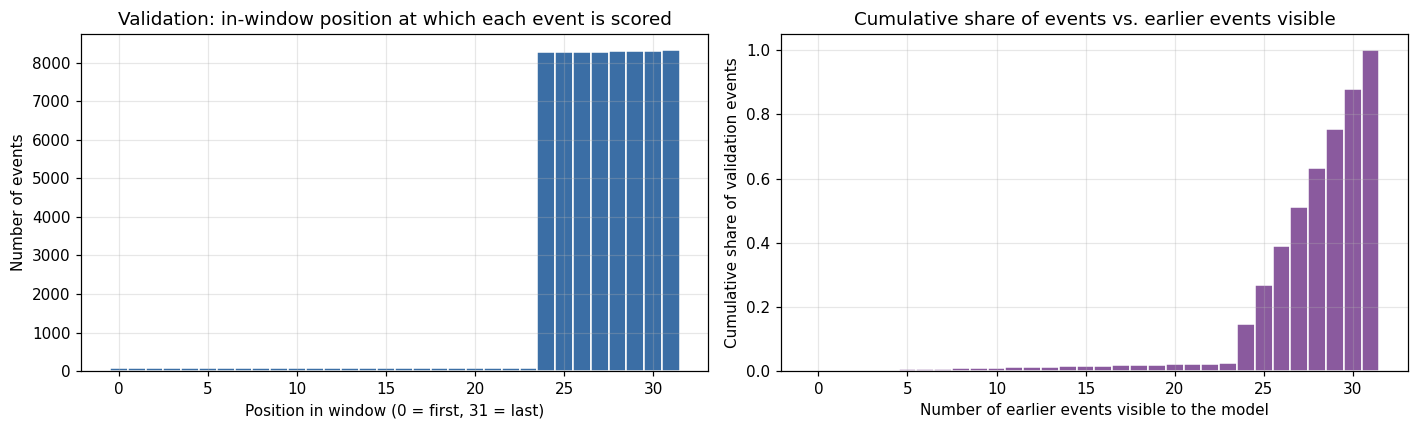

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4))

view = evaluation_views["val"]
axes[0].hist(view["position"], bins=np.arange(-0.5, 32.5, 1), color="#3b6ea5", edgecolor="white")
axes[0].set_title("Validation: in-window position at which each event is scored")
axes[0].set_xlabel("Position in window (0 = first, 31 = last)")
axes[0].set_ylabel("Number of events")

history_available = view["position"]
axes[1].hist(history_available, bins=np.arange(-0.5, 32.5, 1), cumulative=True, density=True,
             color="#8a5a9e", edgecolor="white")
axes[1].set_title("Cumulative share of events vs. earlier events visible")
axes[1].set_xlabel("Number of earlier events visible to the model")
axes[1].set_ylabel("Cumulative share of validation events")
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_evaluation_view_positions.png", bbox_inches="tight")
plt.show()

**What the figure shows.** Left: for each validation event, the position (0–31) at which it is scored in the evaluation view. Right: the cumulative share of events against how many earlier events the model can see for them.

**Purpose of the figure.** It shows how much history the model has when it is evaluated, which affects how results are read.

**What it shows.** Almost all events are scored at positions 24–31, i.e. with 24–31 earlier events visible. Only the first 24 events of each period are scored earlier in the window, because there is no earlier history in that period.

**What it means for the research.** Reported metrics describe predictions made with (almost) the full 32-event context. Training still uses all positions, so the model also learns to predict with short history.

**What cannot be concluded.** This chart says nothing about whether the model *uses* the history; that is measured later by comparing performance at different positions and context lengths.

## 7. Vocabularies must come from the training split only

A *vocabulary* maps raw ids (a team id, a position id, a competition id) to consecutive integers used by the model's lookup tables. If validation or test data decided which ids get an entry, held-out data would influence the model's design.

The dataset contains indices built earlier (`team_ix`, `role_ix`, `comp_ix`). They are rebuilt here from the training split only, with **index 0 reserved for "not seen in training"**, and compared with the stored ones. The player index is rebuilt in notebook 02, because its threshold is itself an experiment.

In [ ]:
def rebuild_train_vocabulary(column):
    train_values = sorted(events.loc[events["split"] == "train", column].unique())
    vocabulary = {}
    for position, value in enumerate(train_values):
        vocabulary[value] = position + 1          # 0 is reserved for "unseen in training"
    return vocabulary

vocabulary_rows = []
for raw_column, stored_column in [("team_id", "team_ix"), ("position_id", "role_ix"), ("competition_id", "comp_ix")]:
    vocabulary = rebuild_train_vocabulary(raw_column)
    rebuilt_index = events[raw_column].map(vocabulary).fillna(0).astype(int)
    # the stored index may use a different ordering; compare the partition it induces instead
    same_partition = (pd.crosstab(rebuilt_index, events[stored_column]) > 0).sum(axis=1).max() == 1
    vocabulary_rows.append({
        "feature": raw_column,
        "distinct values (all splits)": events[raw_column].nunique(),
        "values seen in train": len(vocabulary),
        "val/test events with unseen value": int(((rebuilt_index == 0) & (events["split"] != "train")).sum()),
        "stored index distinct values": events[stored_column].nunique(),
        "rebuilt index agrees with stored grouping": bool(same_partition),
    })
pd.DataFrame(vocabulary_rows).set_index("feature")

,distinct values (all splits),values seen in train,val/test events with unseen value,stored index distinct values,rebuilt index agrees with stored grouping
feature,,,,,
team_id,228,213,18661,214,True
position_id,25,25,0,25,True
competition_id,21,20,3915,21,True


**RESULT.** The table compares the train-only vocabularies with the stored indices.

**OBSERVATION.** All 25 roles occur in training. 15 of the 228 teams and 1 of the 21 competitions never occur in training: 18,661 validation/test events (about 14% of held-out events) belong to a team unseen in training, and 3,915 to the competition unseen in training.

**INTERPRETATION.** Those held-out events receive index 0 (no dedicated team or competition vector). This is correct behaviour, not a defect: the model cannot have learned anything about a team it never saw.

**SCIENTIFIC SIGNIFICANCE.** Unseen-team events are a natural "identity absent" subgroup. Their share is large enough that results are also reported separately for events with and without a known team (notebook 06), because mixing them would blur any identity effect.

**Decision.** All identity vocabularies are rebuilt from train only (notebook 02) and saved with the encoding. The stored `*_ix` columns are not used by the model.

## 8. Leakage audits

Leakage means the input contains information about the answer. Four specific risks are tested.

### 8.1 Possession-derived features

**The concern.** StatsBomb assigns possession numbers *after the fact*, using knowledge of what happened. When a defender wins the ball with a recovery or an interception, StatsBomb often starts a new possession **at that event**. When a defender clears the ball, StatsBomb usually keeps the attacking team's possession going. So whether an event "starts a new possession" may depend on what the action *is* — which is exactly what the model must predict.

Four input features come from the current event's possession number: `new_possession`, `poss_len`, `play_pattern_id` and `t_poss`. If they encode the action type, the model can partly read the answer from them.

**The test.** Consider only events where the acting team differs from the previous event's acting team (a situation that is known before the action, because the actor is known). Then compare the action distribution for events flagged as a new possession with those that are not.

In [ ]:
previous_team = group["team_id"].shift(1)
team_changed = (events["team_id"] != previous_team) & ~is_first_in_period

subset = events[team_changed]
possession_table = pd.crosstab(subset["action"], subset["new_possession"], normalize="columns") * 100
possession_table.columns = ["new_possession = 0 (%)", "new_possession = 1 (%)"]
possession_table = possession_table.loc[data.ACTION_NAMES].round(1)
print("Events where the acting team changed:", len(subset))
possession_table

Events where the acting team changed: 164081


,new_possession = 0 (%),new_possession = 1 (%)
action,,
PASS_SHORT,13.3,39.4
PASS_LONG,5.5,28.7
CROSS,0.2,0.2
CARRY,0.0,0.0
DRIBBLE,0.1,0.0
SHOT,0.7,0.1
CLEARANCE,11.3,0.0
RECOVERY,17.3,16.9
INTERCEPTION,16.5,3.2


In [ ]:
def entropy_nats(probabilities):
    probabilities = probabilities[probabilities > 0]
    return float(-(probabilities * np.log(probabilities)).sum())

def conditional_entropy(target, condition):
    """H(target | condition) in nats, from counts on the TRAIN split only."""
    table = pd.crosstab(condition, target)
    total = table.values.sum()
    value = 0.0
    for _, row in table.iterrows():
        row_total = row.sum()
        value += (row_total / total) * entropy_nats(row.values / row_total)
    return value

train_rows = events["split"] == "train"
action_train = events.loc[train_rows, "action_id"]
base_condition = (events.loc[train_rows, "prev_action_id"].astype(str) + "_"
                  + team_changed[train_rows].astype(int).astype(str))

information_rows = []
h_base = conditional_entropy(action_train, base_condition)
for feature in ["new_possession", "poss_len", "play_pattern_id"]:
    condition = base_condition + "_" + events.loc[train_rows, feature].astype(str)
    h_with = conditional_entropy(action_train, condition)
    information_rows.append({"added feature": feature,
                             "H(action | prev action, team change)": round(h_base, 4),
                             "H(action | ... + feature)": round(h_with, 4),
                             "information gained (nats)": round(h_base - h_with, 4)})
print("Entropy of the action class, H(action):", round(entropy_nats(action_train.value_counts(normalize=True).values), 4), "nats")
pd.DataFrame(information_rows).set_index("added feature")

Entropy of the action class, H(action): 2.0017 nats


,"H(action | prev action, team change)",H(action | ... + feature),information gained (nats)
added feature,,,
new_possession,1.3735,1.3210,0.0525
poss_len,1.3735,1.2953,0.0782
play_pattern_id,1.3735,1.3291,0.0444


**RESULT.** When the acting team has changed, events flagged `new_possession = 1` are never CLEARANCE, FOUL_WON or LOSS, while events flagged 0 contain thousands of them. Recoveries and interceptions are split between the two flags in a way that tracks StatsBomb's rule for when a defensive action counts as winning possession.

**OBSERVATION.** Given the previous action and whether the acting team changed (both knowable before the action), each possession feature still removes a measurable amount of uncertainty about the action (the "information gained" column, in nats — a unit of information; 0 would mean no extra information).

**INTERPRETATION.** Part of that information is legitimate (a long possession really does change what players do). But part is not available before the action: the flag and the counters are *set by* the type of action at the current event. The two cannot be cleanly separated with these columns.

**SCIENTIFIC SIGNIFICANCE.** Keeping these features would let the model partly read the answer, inflate accuracy, and, for the later mechanistic analysis, create a shortcut that is neither identity nor genuine context.

**Correction (smallest defensible change).** The four possession features are replaced by the same quantities **as they stood at the previous event**, which is fully known before the current action:

| Original (depends on the current event's possession number) | Replacement (known before the action) |
|---|---|
| `new_possession` — first event of a possession | `team_change` — the acting team differs from the previous event's acting team |
| `poss_len` — events so far in the current possession | `prev_poss_len` — `poss_len` of the previous event (21 = no previous event) |
| `play_pattern_id` — how the current possession began | `prev_play_pattern_id` — play pattern of the previous event's possession (0 = none) |
| `t_poss` — seconds since the current possession began | `t_poss_prev` — seconds from the start of the previous event's possession to now, log(1+s), clipped at 600 s |

The replacement keeps the same number of inputs, the same factor groups and the same meaning (how far the current spell of play has progressed), but each value is computed only from completed events. The original columns remain in the dataset, so the original encoding can be reproduced for comparison. The effect of the change on predictive performance is measured with a linear model in notebook 02.

The correction changes the definition of four input features. It does not change the research question, the target, the split or the architecture.

In [ ]:
%%writefile -a src/data.py

def add_pre_action_possession_features(events):
    """Add possession features computed only from events that have already happened.

    team_change          1 if the acting team differs from the previous event's acting team
    prev_poss_len        poss_len of the previous event (21 = no previous event in the period)
    prev_play_pattern_id play pattern of the previous event's possession (0 = none)
    t_poss_prev          log(1 + seconds from the start of the previous event's possession
                         until the current event), clipped at 600 seconds

    Why: StatsBomb possession numbers are assigned after the fact, so the original columns
    (new_possession, poss_len, play_pattern_id, t_poss) can depend on the action at the
    current event. See notebook 01, Section 8.1.
    """
    group = events.groupby(["match_id", "period"])
    is_first = events["period_offset"] == 0

    previous_team = group["team_id"].shift(1)
    team_change = (events["team_id"] != previous_team).astype("int64")
    team_change[is_first] = 0
    events["team_change"] = team_change

    previous_poss_len = group["poss_len"].shift(1)
    events["prev_poss_len"] = previous_poss_len.fillna(21).astype("int64")

    previous_play_pattern = group["play_pattern_id"].shift(1)
    events["prev_play_pattern_id"] = previous_play_pattern.fillna(0).astype("int64")

    possession_start_time = events.groupby(["match_id", "period", "possession"])["t_period_s"].transform("min")
    previous_possession_start = possession_start_time.groupby([events["match_id"], events["period"]]).shift(1)
    elapsed_seconds = events["t_period_s"] - previous_possession_start
    elapsed_seconds = elapsed_seconds.fillna(0.0).clip(lower=0.0, upper=600.0)
    events["t_poss_prev"] = np.log1p(elapsed_seconds).astype("float32")
    return events


def add_coupled_event_flag(events):
    """Flag events recorded at the same moment as the previous event (gap below 0.01 s).

    StatsBomb records some events in pairs with one timestamp (for example Foul Committed
    followed by Foul Won). The second event of such a pair is almost determined by the first,
    so it measures annotation structure rather than a player decision. Metrics are reported
    with and without these events.
    """
    seconds_since_previous = np.expm1(events["dt"].astype("float64"))
    is_first = events["period_offset"] == 0
    events["coupled_with_prev"] = ((seconds_since_previous < 0.01) & ~is_first).astype("int64")
    return events

Appending to src/data.py


In [ ]:
importlib.reload(data)
events = data.add_pre_action_possession_features(events)
events = data.add_coupled_event_flag(events)

# Repeat the information test with the replacement features.
replacement_rows = []
for original, replacement in [("new_possession", "team_change"), ("poss_len", "prev_poss_len"),
                              ("play_pattern_id", "prev_play_pattern_id")]:
    for feature in [original, replacement]:
        condition = base_condition + "_" + events.loc[train_rows, feature].astype(str)
        replacement_rows.append({"feature": feature,
                                 "type": "original" if feature == original else "pre-action replacement",
                                 "information gained beyond (prev action, team change), nats":
                                     round(h_base - conditional_entropy(action_train, condition), 4)})
pd.DataFrame(replacement_rows).set_index("feature")

,type,"information gained beyond (prev action, team change), nats"
feature,,
new_possession,original,0.0525
team_change,pre-action replacement,0.0000
poss_len,original,0.0782
prev_poss_len,pre-action replacement,0.0274
play_pattern_id,original,0.0444
prev_play_pattern_id,pre-action replacement,0.0203


**How to read this table.** `team_change` is part of the baseline condition, so its extra information is zero by construction. The other replacements still carry information about the action, but now only information available before the action. Where the original feature carried more information than its replacement, the difference is an upper bound on what the original leaked (it may also include legitimate information lost by looking one event back).

### 8.2 Annotation-coupled events

**The concern.** Some events are recorded in pairs at the same timestamp. The clearest case: a Foul Committed is immediately followed by the matching Foul Won. The second event is predictable from the first without any football understanding.

In [ ]:
coupled = events[events["coupled_with_prev"] == 1]
previous_action_name = group["action"].shift(1)
coupled_pairs = pd.crosstab(previous_action_name[coupled.index], coupled["action"])
top_pairs = coupled_pairs.stack().sort_values(ascending=False).head(8)

foul_won_total = int((events["action"] == "FOUL_WON").sum())
foul_won_after_foul = int(((events["action"] == "FOUL_WON") & (previous_action_name == "FOUL_COMMITTED")
                           & (events["coupled_with_prev"] == 1)).sum())
print(f"Coupled events: {len(coupled)} ({100 * len(coupled) / len(events):.1f}% of all events)")
print(f"FOUL_WON events directly after a same-time FOUL_COMMITTED: {foul_won_after_foul} of {foul_won_total} "
      f"({100 * foul_won_after_foul / foul_won_total:.1f}%)")
print("\nMost frequent (previous action -> current action) pairs among coupled events:")
top_pairs.rename("count").to_frame()

Coupled events: 68419 (10.4% of all events)
FOUL_WON events directly after a same-time FOUL_COMMITTED: 9104 of 9124 (99.8%)

Most frequent (previous action -> current action) pairs among coupled events:


count
action         action           
RECOVERY       CARRY       20882
LOSS           DUEL         9182
FOUL_COMMITTED FOUL_WON     9104
DRIBBLE        CARRY        5692
               DUEL         4622
DUEL           PASS_SHORT   4481
               CLEARANCE    2923
               CARRY        2825

**RESULT.** About one event in ten shares its timestamp with the previous event. 99.8% of FOUL_WON events are the second half of a same-moment Foul Committed / Foul Won pair.

**OBSERVATION.** The flag is broad: the most frequent coupled pair is a RECOVERY followed by a CARRY starting at the same timestamp, which is an ordinary football sequence rather than a duplicate record. Other frequent pairs (LOSS → DUEL, DRIBBLE → DUEL) are the two sides of one contest recorded as two events.

**INTERPRETATION.** FOUL_WON will be predicted almost perfectly for annotation reasons. This inflates accuracy and FOUL_WON's per-class score but is not a modelling error. Because the flag also catches ordinary same-moment sequences, removing all coupled events is a *conservative* robustness check: it removes some genuine decisions along with the annotation pairs.

**Decision.** The events stay in the data (removing them would change the dataset). The final evaluation (notebook 06) reports every headline metric also **without** coupled events, so that performance on genuine decisions is visible.

### 8.3 Score timing

**The concern.** `score_diff_idx` must describe the score *before* the event. If a scoring shot already carried the new score, the input would reveal that the shot scored.

**The test.** The score is converted to a single perspective per match (the first team listed in the match). A change of that score between two consecutive events marks a goal. The goal must appear **after** the scoring event, i.e. the event where the new score first appears must not itself be the shot; the event immediately before the change should be a SHOT (or OTHER, which contains own goals).

In [ ]:
first_team = events.groupby("match_id")["team_id"].transform("first")
score_from_acting_team = events["score_diff_idx"].astype(int) - 3
score_first_team_view = np.where(events["team_id"] == first_team, score_from_acting_team, -score_from_acting_team)
events["_score_view"] = score_first_team_view

previous_score = group["_score_view"].shift(1)
score_changes = events[(events["_score_view"] != previous_score) & ~is_first_in_period]
action_before_change = previous_action_name[score_changes.index]
print("Score changes detected between consecutive events:", len(score_changes))
print("\nAction of the event just BEFORE the score changed:")
print(action_before_change.value_counts().to_string())
print("\nAction of the event where the new score first appears:")
print(score_changes["action"].value_counts().head(6).to_string())
events = events.drop(columns=["_score_view"])

Score changes detected between consecutive events: 951

Action of the event just BEFORE the score changed:
action
SHOT     942
OTHER      9

Action of the event where the new score first appears:
action
GK_ACTION       880
INTERCEPTION     59
OTHER             6
PASS_SHORT        3
LOSS              2
PASS_LONG         1


**RESULT.** Every one of the 951 score changes is immediately preceded by a SHOT (942) or an OTHER event (9, own goals). No scoring shot carries the new score.

**OBSERVATION.** The first event carrying the new score is almost always a GK_ACTION (880 cases): StatsBomb records a goalkeeper "goal conceded" entry immediately after a goal.

**INTERPRETATION.** The score is updated *after* the scoring event, so `score_diff_idx` is pre-action information for the shot. For the goalkeeper record that follows, a score change relative to the previous event signals "a goal has just been conceded" — which is true before that record, so it is not leakage, but it makes that GK_ACTION easy to predict. These records are same-moment events and are therefore included in the coupled-event robustness check (Section 8.2).

**Verdict.** PASS.

### 8.4 Post-action columns never reach the model

Columns that describe the action's result (`end_zone`, `type_name`, `action`) must not change the model input. The input for an event is built only from the 19 input features listed in Section 10. The check below perturbs every target-side column at random and verifies that the encoded input is unchanged. It uses the feature-building function written in notebook 02, so here it checks the list of source columns that function reads.

In [ ]:
# The model's input builder (notebook 02) reads exactly these source columns.
INPUT_SOURCE_COLUMNS = [
    "player_id", "team_id", "position_id", "competition_id",          # identity
    "zone", "x_norm", "y_norm",                                        # space
    "period", "minute_bin", "dt", "t_poss_prev",                       # time
    "score_diff_idx", "prev_play_pattern_id", "prev_poss_len", "team_change",   # game state
    "prev_action_id", "prev_outcome", "prev_end_zone", "same_player_as_prev",   # history
]
TARGET_SIDE_COLUMNS = ["action", "action_id", "type_name", "end_zone"]
overlap = sorted(set(INPUT_SOURCE_COLUMNS) & set(TARGET_SIDE_COLUMNS))
print("Input source columns:", len(INPUT_SOURCE_COLUMNS))
print("Target-side columns among the inputs:", overlap if overlap else "none")

Input source columns: 19
Target-side columns among the inputs: none


## 9. Target distribution

**Why this matters.** When some classes are much rarer than others, a model can score high accuracy by predicting the common classes and ignoring the rare ones. The class distribution decides which metrics must be reported.

In [ ]:
class_counts = pd.crosstab(events["action"], events["split"]).loc[data.ACTION_NAMES, ["train", "val", "test"]]
class_share = (100 * class_counts / class_counts.sum()).round(2)
distribution_table = class_counts.copy()
for split_name in ["train", "val", "test"]:
    distribution_table[f"{split_name} %"] = class_share[split_name]
distribution_table["total"] = class_counts.sum(axis=1)
distribution_table = distribution_table.sort_values("total", ascending=False)
largest = distribution_table["total"].max()
smallest = distribution_table["total"].min()
print(f"Imbalance ratio (largest / smallest class): {largest / smallest:.0f}")
print("Classes below 1% of events:", list(distribution_table.index[distribution_table["total"] / distribution_table["total"].sum() < 0.01]))
distribution_table

Imbalance ratio (largest / smallest class): 305
Classes below 1% of events: ['OTHER']


split,train,val,test,train %,val %,test %,total
action,,,,,,,
PASS_SHORT,158992,21814,19314,30.23,32.08,29.71,200120
CARRY,115591,15021,14281,21.98,22.09,21.97,144893
PASS_LONG,106375,13152,12973,20.23,19.34,19.96,132500
RECOVERY,30516,3814,3861,5.80,5.61,5.94,38191
DUEL,21036,2486,2667,4.00,3.66,4.10,26189
INTERCEPTION,17414,2283,2202,3.31,3.36,3.39,21899
LOSS,15696,1965,2033,2.98,2.89,3.13,19694
CLEARANCE,12640,1465,1637,2.40,2.15,2.52,15742
DRIBBLE,9899,1213,1170,1.88,1.78,1.80,12282


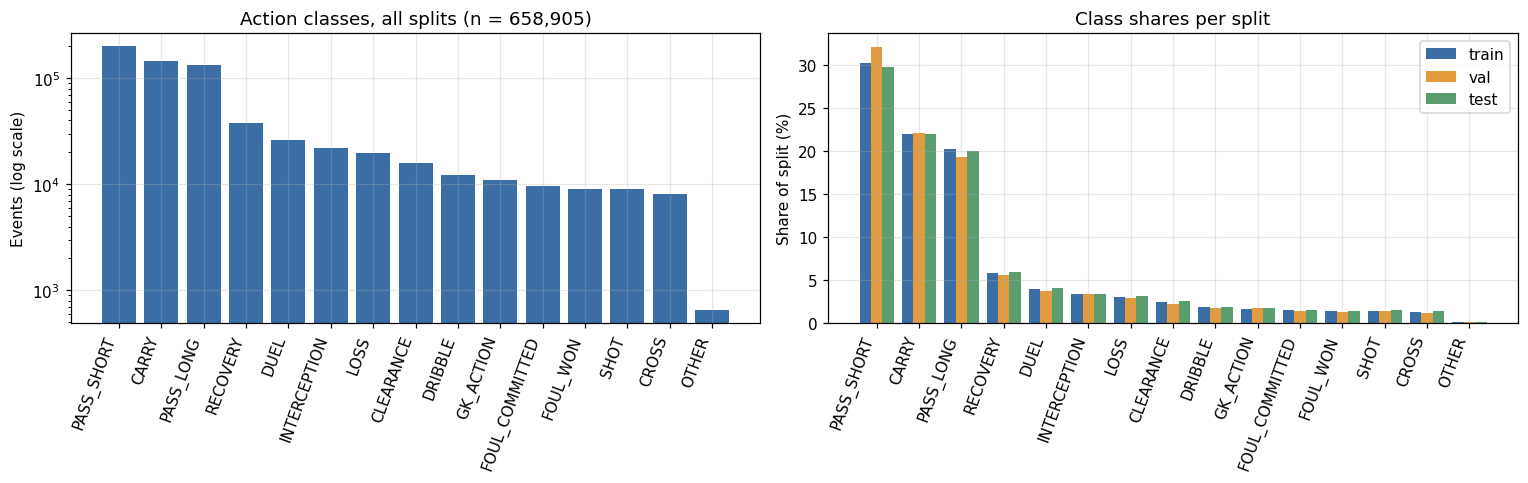

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5))
order = distribution_table.index.tolist()
positions = np.arange(len(order))
axes[0].bar(positions, distribution_table["total"], color="#3b6ea5")
axes[0].set_xticks(positions)
axes[0].set_xticklabels(order, rotation=70, ha="right")
axes[0].set_yscale("log")
axes[0].set_ylabel("Events (log scale)")
axes[0].set_title(f"Action classes, all splits (n = {len(events):,})")

width = 0.27
for offset, split_name, colour in [(-width, "train", "#3b6ea5"), (0, "val", "#e39b3b"), (width, "test", "#5a9e6f")]:
    axes[1].bar(positions + offset, distribution_table[f"{split_name} %"], width=width, label=split_name, color=colour)
axes[1].set_xticks(positions)
axes[1].set_xticklabels(order, rotation=70, ha="right")
axes[1].set_ylabel("Share of split (%)")
axes[1].set_title("Class shares per split")
axes[1].legend()
plt.tight_layout()
plt.savefig(FIGURES_DIR / "01_class_distribution.png", bbox_inches="tight")
plt.show()

**What the figure shows.** Left: number of events per action class (log scale, so rare classes remain visible). Right: each class's share of events in train, validation and test.

**What it shows.** Three classes (short pass, carry, long pass) dominate; SHOT, CROSS, OTHER and several defensive classes are rare. The three splits have very similar class shares.

**What it means for the research.**

1. Accuracy alone would mostly measure the common classes, so **macro-F1** (defined in notebook 02: the average of per-class F1 scores, each class weighted equally) and **per-class** results are always reported.
2. **No rebalancing.** Class weighting or resampling would change the probabilities the model outputs. The later mechanistic analysis uses exactly those probabilities (the difference in log-probability between two actions), so the model is trained on the natural class frequencies. If a class collapses (never predicted), that is reported; a weighted model would then be a separate, labelled comparison, not a replacement.
3. Similar shares across splits mean validation results should be representative of test results.

**What cannot be concluded.** Similar class shares do not guarantee similar difficulty: the matches in each split differ in competition and teams.

## 10. Final feature specification

The table lists the 19 model inputs (after the possession correction), the factor group each belongs to, and how it is encoded. A *factor group* is a set of inputs that is turned into one vector; the model's input for an event is the **sum** of one vector per group (the *factorised event representation*, explained in notebook 03). Keeping groups separate means that any one of them — for example the player — can later be removed or replaced on its own.

In [ ]:
feature_specification = pd.DataFrame([
    # feature, source column(s), pre-action, encoding, train-derived vocabulary, leakage risk, factor group, scientific role
    ("player", "player_id", "yes", "embedding; index 0 = no dedicated identity (fixed zero vector)", "yes (threshold on train counts)", "low", "player", "identity under study"),
    ("team", "team_id", "yes", "embedding; index 0 = unseen team (zero)", "yes", "low", "team", "identity (team habits)"),
    ("role", "position_id", "yes", "embedding; index 0 = unseen role (zero)", "yes", "low", "role", "identity; controls for position"),
    ("competition", "competition_id", "yes", "embedding; index 0 = unseen (zero)", "yes", "low", "competition", "controls league/annotation style; nested with identity"),
    ("zone", "zone", "yes", "embedding (96 cells)", "no", "low", "space", "context: where"),
    ("x_norm, y_norm", "x_norm, y_norm", "yes", "linear projection, no bias", "no", "low", "space", "context: precise location"),
    ("period", "period", "yes", "embedding (4)", "no", "low", "time", "context: when"),
    ("minute_bin", "minute_bin", "yes", "embedding (24)", "no", "low", "time", "context: match clock"),
    ("dt", "dt", "yes", "linear projection, no bias", "no", "medium (coupled events, reported separately)", "time", "context: tempo"),
    ("t_poss", "t_poss_prev (replaces t_poss)", "yes", "linear projection, no bias", "no", "low after correction", "time", "context: possession age"),
    ("score_diff", "score_diff_idx", "yes (verified)", "embedding (7)", "no", "low", "state", "context: score"),
    ("play_pattern", "prev_play_pattern_id (replaces play_pattern_id)", "yes", "embedding (10)", "no", "low after correction", "state", "context: phase of play"),
    ("poss_len", "prev_poss_len (replaces poss_len)", "yes", "embedding (22)", "no", "low after correction", "state", "context: possession length"),
    ("possession_flag", "team_change (replaces new_possession)", "yes", "embedding (2)", "no", "low after correction", "state", "context: turnover of actor team"),
    ("prev_action", "prev_action_id", "yes", "embedding (16, incl. END)", "no", "low", "history", "context: previous action"),
    ("prev_outcome", "prev_outcome", "yes", "embedding (3)", "no", "low", "history", "context: previous success"),
    ("prev_end_zone", "prev_end_zone", "yes", "embedding (96)", "no", "low", "history", "context: where the previous action ended"),
    ("same_player_as_prev", "same_player_as_prev", "yes", "embedding (2)", "no", "low", "history", "context: same actor continues"),
    ("position in window", "(window index 0–31)", "yes", "learned positional embedding (32)", "no", "low", "position", "order of events"),
], columns=["feature", "source", "pre-action?", "encoding", "train-derived?", "leakage risk", "factor group", "scientific role"])
feature_specification.to_csv(ARTIFACTS_DIR / "feature_spec.csv", index=False)
feature_specification

,feature,source,pre-action?,encoding,train-derived?,leakage risk,factor group,scientific role
0,player,player_id,yes,embedding; index 0 = no dedicated identity (fixed zero vector),yes (threshold on train counts),low,player,identity under study
1,team,team_id,yes,embedding; index 0 = unseen team (zero),yes,low,team,identity (team habits)
2,role,position_id,yes,embedding; index 0 = unseen role (zero),yes,low,role,identity; controls for position
3,competition,competition_id,yes,embedding; index 0 = unseen (zero),yes,low,competition,controls league/annotation style; nested with identity
4,zone,zone,yes,embedding (96 cells),no,low,space,context: where
5,"x_norm, y_norm","x_norm, y_norm",yes,"linear projection, no bias",no,low,space,context: precise location
6,period,period,yes,embedding (4),no,low,time,context: when
7,minute_bin,minute_bin,yes,embedding (24),no,low,time,context: match clock
8,dt,dt,yes,"linear projection, no bias",no,"medium (coupled events, reported separately)",time,context: tempo
9,t_poss,t_poss_prev (replaces t_poss),yes,"linear projection, no bias",no,low after correction,time,context: possession age


**Note on `play_pattern`.** The table lists the play-pattern input as prepared in this notebook. It is not used as a model input in the later notebooks. A separate temporal check of the raw StatsBomb annotation showed that the play-pattern label is assigned from how the whole possession develops (for example, the "From Counter" label depends on the directness and length of the attack), so even the value of the previous event can carry information from after the prediction point. The feature is therefore excluded from the model; the remaining 18 inputs are unchanged.

**Note on competition.** Players are nested inside competitions (a player usually plays in one league in this data). The competition input therefore overlaps with identity. It is kept because leagues differ in style and annotation; any later identity swap must stay within a competition.

**Note on the actor.** The task conditions on *who acts*. In event data the actor is partly determined by the kind of event (for example, a defending-team actor makes a defensive action more likely). Part of any identity effect may therefore reflect how events are recorded. This is stated as a limitation of all identity results.

## 11. Saved outputs

The prepared event table, including the pre-action features derived above, and the audit results are written to disk.

In [ ]:
events.to_parquet(ARTIFACTS_DIR / "events_prepared.parquet", index=False)

audit_report = {
    "dataset_sha256": dataset_hash,
    "n_events": int(len(events)),
    "split_summary": split_summary[["matches", "events"]].to_dict(),
    "matches_in_more_than_one_split": matches_in_more_than_one_split,
    "sequence_checks": sequence_checks,
    "window_counts_K32_stride8": window_counts,
    "window_problems": window_problems,
    "evaluation_view": coverage_table.reset_index().to_dict(orient="records"),
    "possession_leakage_information_gain_nats": {row["added feature"]: row["information gained (nats)"] for row in information_rows},
    "possession_feature_decision": "PROVISIONAL: replace new_possession, poss_len, play_pattern_id, t_poss "
                                   "with team_change, prev_poss_len, prev_play_pattern_id, t_poss_prev",
    "coupled_events": {"count": int(len(coupled)), "share": float(len(coupled) / len(events)),
                       "foul_won_after_same_time_foul_committed": foul_won_after_foul,
                       "foul_won_total": foul_won_total},
    "score_timing": "score updated after the scoring event (see Section 8.3)",
    "class_imbalance_ratio": float(largest / smallest),
    "class_rebalancing": "none (natural frequencies; macro-F1 and per-class metrics reported)",
}
with open(ARTIFACTS_DIR / "audit_report.json", "w") as handle:
    json.dump(audit_report, handle, indent=2, default=str)
print("Saved:", ARTIFACTS_DIR / "events_prepared.parquet")
print("Saved:", ARTIFACTS_DIR / "audit_report.json")

Saved: /home/claude/work/track_a/artifacts/events_prepared.parquet
Saved: /home/claude/work/track_a/artifacts/audit_report.json


## 12. Audit summary

| Area | Finding |
|---|---|
| Schema | Every column documented; no missing values. |
| Split | Match-level; no match in more than one split; counts as specified (280 / 35 / 35 matches). |
| Sequence order and history columns | All nine checks pass. |
| Windows | 79,934 windows at K = 32, stride 8; none crosses a match or period boundary. |
| Evaluation view | Every event is scored exactly once, in the window with the most preceding history. |
| Vocabularies | Rebuilt from the training split only; 15 teams and 1 competition are absent from training. |
| Possession-derived features | Their values depend on the current action. They are replaced by versions computed from the previous event. |
| Annotation-coupled events (~10%) | Flagged; metrics are reported with and without them. |
| Score timing | The score is updated after the scoring event, so the score input is pre-action. |
| Target-side columns | Not used as inputs. |
| Class imbalance | Large (imbalance ratio in Section 9); no rebalancing; macro-F1 and per-class metrics are reported. |

**What this notebook does not establish.** It shows that the data is internally consistent and that the inputs are pre-action. It does not show that the chosen features are *sufficient* to predict actions well; that is measured by the baselines and the Transformer.